[SARSA] main training: 10000 episodes, alpha=0.8, gamma=0.9, epsilon=0.1
Q-value & Greedy Policy (original course renderer)


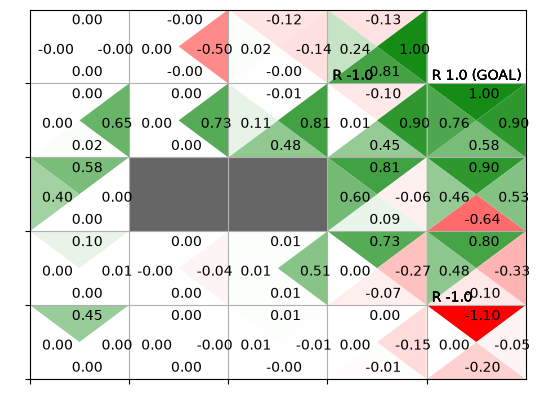

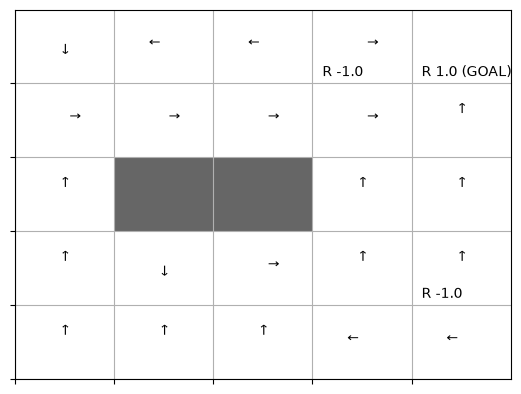

Greedy evaluation (eps=0)   return=  1.000 | goal=100.0% | risk=  0.0% | steps(success)=   8.0
Behavior evaluation (eps=0.1) return=  0.980 | goal=100.0% | risk=  2.0% | steps(success)=  10.3


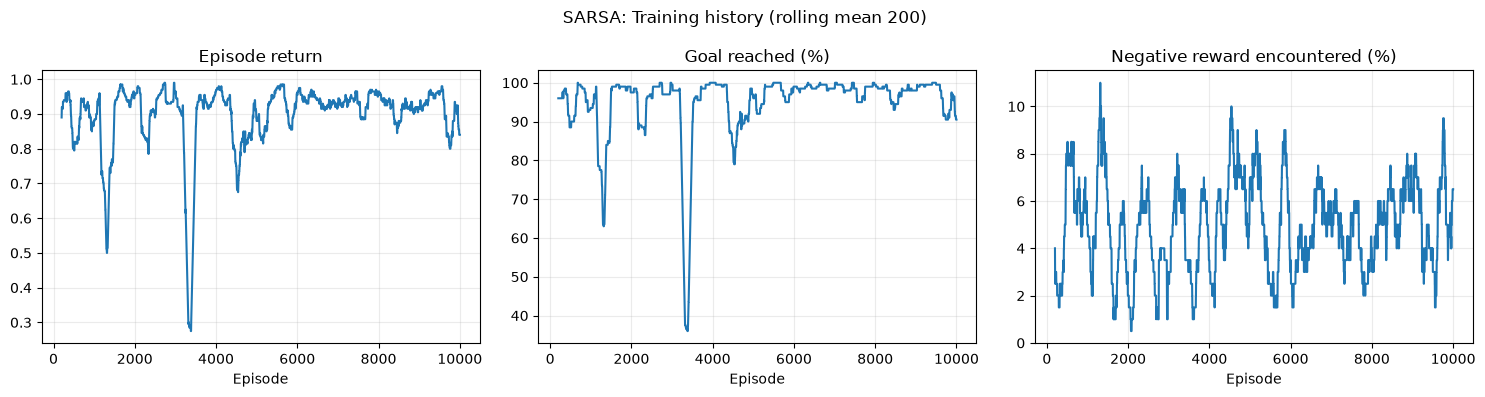


[Epsilon sweep]
  epsilon=0.0: done (3 seeds)
  epsilon=0.05: done (3 seeds)
  epsilon=0.1: done (3 seeds)
  epsilon=0.3: done (3 seeds)
  epsilon=0.5: done (3 seeds)
epsilon=0.0 : greedy_return=1.000, behavior_return=1.000, greedy_goal=100.0%, behavior_risk=0.0%
epsilon=0.05: greedy_return=0.333, behavior_return=0.955, greedy_goal=33.3%, behavior_risk=1.7%
epsilon=0.1 : greedy_return=1.000, behavior_return=0.965, greedy_goal=100.0%, behavior_risk=3.5%
epsilon=0.3 : greedy_return=0.333, behavior_return=0.828, greedy_goal=33.3%, behavior_risk=15.3%
epsilon=0.5 : greedy_return=0.000, behavior_return=0.543, greedy_goal=0.0%, behavior_risk=31.8%


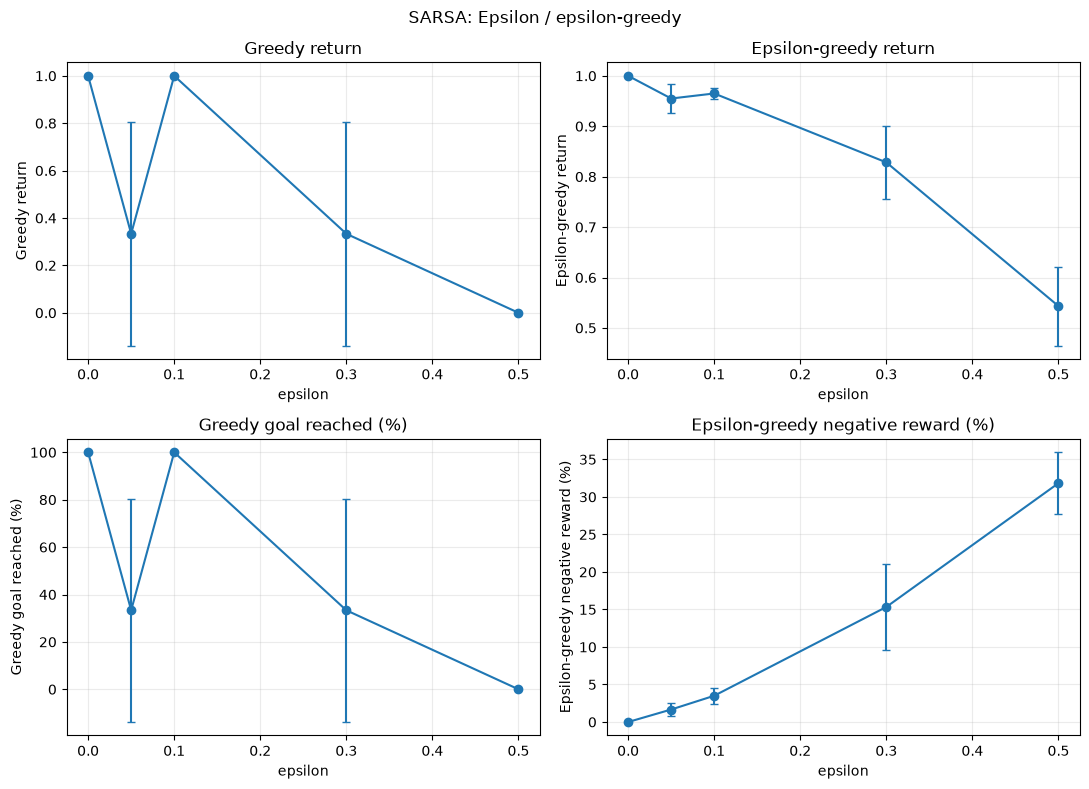


[Alpha sweep]
  alpha=0.1: done (3 seeds)
  alpha=0.3: done (3 seeds)
  alpha=0.8: done (3 seeds)

[Gamma sweep]
  gamma=0.5: done (3 seeds)
  gamma=0.9: done (3 seeds)
  gamma=0.99: done (3 seeds)


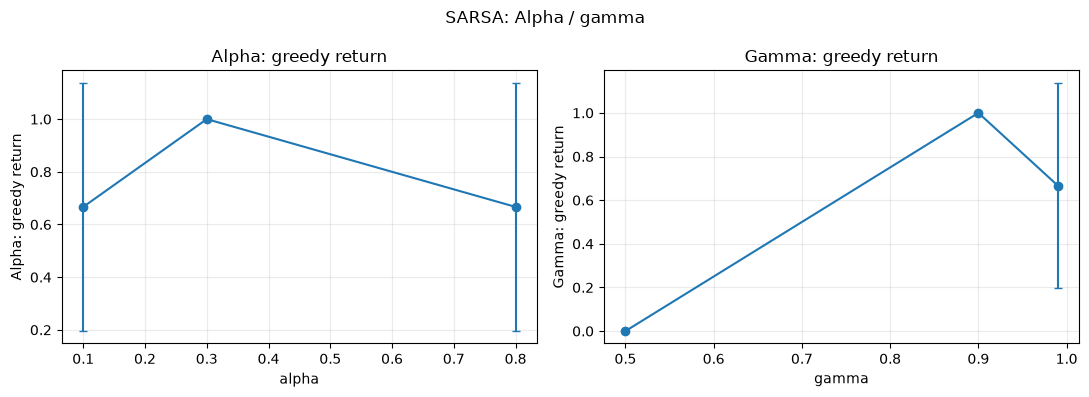


[Epsilon schedule: fixed vs linearly decaying]
  fixed_0.1: return=0.972, goal=100.0%, risk=2.8%
  linear_0.5_to_0.05: return=0.983, goal=99.8%, risk=1.5%


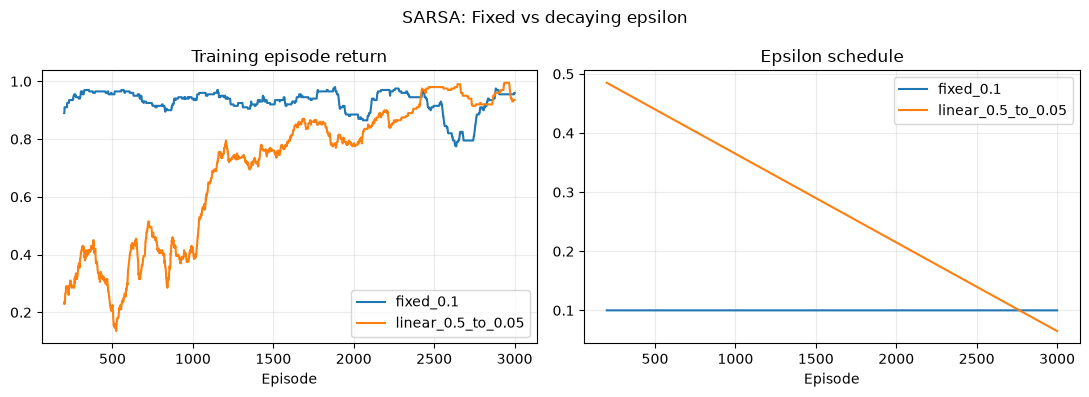


Done. Outputs: C:\Users\user\OneDrive\문서\2026\강화학습\Homework\7. Temporal Difference Method\sarsa_results
Elapsed: 31.8 s


In [1]:
# SARSA - Single-cell notebook (independent experiment)
# Existing course GridWorld and greedy_probs are used unchanged.
# Run this entire cell once in the original assignment project.
import sys
import csv
import time
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

# Locate the original common package from the working directory or parents.
for project_root in (Path.cwd(), *list(Path.cwd().parents)[:5]):
    if (project_root / 'common' / 'gridworld.py').is_file():
        if str(project_root) not in sys.path:
            sys.path.insert(0, str(project_root))
        break
try:
    from common.gridworld import GridWorld
    from common.utils import greedy_probs
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        'Could not import common.gridworld/common.utils. '
        'Run the notebook inside the original GridWorld project.'
    ) from exc

# ----------------------- Experiment parameters -----------------------
ALPHA = 0.8
GAMMA = 0.9
EPSILON = 0.1
MAIN_EPISODES = 10_000
SWEEP_EPISODES = 3_000
SEEDS = [42, 43, 44]
EVAL_EPISODES = 200
MAX_STEPS = 200              # Upper bound for episodes without reaching goal.
SMOOTH_WINDOW = 200
EPSILON_GRID = [0.0, 0.05, 0.1, 0.3, 0.5]
ALPHA_GRID = [0.1, 0.3, 0.8]
GAMMA_GRID = [0.5, 0.9, 0.99]
EPSILON_DECAY_START = 0.5
EPSILON_DECAY_END = 0.05
SAVE_DIR = Path('sarsa_results')
SAVE_DIR.mkdir(exist_ok=True)
start_time = time.perf_counter()

# ----------------------- SARSA agent -----------------------
class SarsaAgent:
    def __init__(self, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON, seed=42):
        self.alpha = float(alpha)
        self.gamma = float(gamma)
        self.epsilon = float(epsilon)
        self.action_size = 4
        self.rng = np.random.default_rng(seed)
        # Preserved from the original: a state starts with a uniform policy.
        random_actions = {a: 1.0 / self.action_size for a in range(self.action_size)}
        self.pi = defaultdict(lambda: random_actions.copy())
        self.Q = defaultdict(float)

    def set_epsilon(self, epsilon):
        if float(epsilon) == self.epsilon:
            return
        self.epsilon = float(epsilon)
        # Needed for a changing epsilon schedule: refresh previously visited states.
        for state in list(self.pi.keys()):
            self.pi[state] = greedy_probs(self.Q, state, self.epsilon,
                                          self.action_size)

    def get_action(self, state, epsilon_override=None, rng=None):
        if epsilon_override is None:
            probabilities = self.pi[state]  # SARSA on-policy behavior
        else:
            probabilities = greedy_probs(self.Q, state,
                                         epsilon_override, self.action_size)
        if rng is None:
            rng = self.rng
        # Fast categorical sampling; matches the original probability dictionary.
        threshold, cumulative, last_action = float(rng.random()), 0.0, 0
        for a, probability in probabilities.items():
            cumulative += probability
            last_action = a
            if threshold < cumulative:
                return int(a)
        return int(last_action)

    def update(self, state, action, reward, next_state, next_action, done):
        # SARSA: Q(s,a) <- Q(s,a) + alpha * [r + gamma*Q(s',a') - Q(s,a)]
        next_q = 0.0 if done else self.Q[next_state, next_action]
        td_target = float(reward) + self.gamma * next_q
        self.Q[state, action] += self.alpha * (td_target - self.Q[state, action])
        self.pi[state] = greedy_probs(self.Q, state, self.epsilon,
                                      self.action_size)

# ----------------------- Train (SARSA only) -----------------------
def train(episodes, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON,
          seed=42, schedule='fixed', epsilon_end=EPSILON_DECAY_END):
    env = GridWorld()
    agent = SarsaAgent(alpha=alpha, gamma=gamma, epsilon=epsilon, seed=seed)
    history = {k: [] for k in ('episode', 'epsilon', 'return', 'success',
                                'risk', 'steps')}

    for episode in range(episodes):
        current_epsilon = (epsilon + (epsilon_end - epsilon) * episode / max(episodes - 1, 1)
                           if schedule == 'linear' else epsilon)
        agent.set_epsilon(current_epsilon)
        state = env.reset()
        action = agent.get_action(state)
        total_reward, hit_risk, success = 0.0, False, False

        for step in range(1, MAX_STEPS + 1):
            next_state, reward, done = env.step(action)
            # Important: SARSA samples a' from the CURRENT behavior policy.
            next_action = None if done else agent.get_action(next_state)
            agent.update(state, action, reward, next_state, next_action, done)
            total_reward += float(reward)
            hit_risk |= float(reward) < 0
            if done:
                success = True
                break
            state, action = next_state, next_action

        history['episode'].append(episode + 1)
        history['epsilon'].append(current_epsilon)
        history['return'].append(total_reward)
        history['success'].append(int(success))
        history['risk'].append(int(hit_risk))
        history['steps'].append(step)

    return agent, history

# ----------------------- Evaluation and results -----------------------
def evaluate(agent, epsilon=0.0, episodes=EVAL_EPISODES, seed=1234):
    # epsilon=0.0: evaluate learned greedy policy.
    # epsilon>0.0: evaluate exploration-inclusive epsilon-greedy policy.
    env = GridWorld()
    rng = np.random.default_rng(seed)
    returns, successes, risks, success_steps = [], [], [], []

    for _ in range(episodes):
        state = env.reset()
        total_reward, hit_risk, success = 0.0, False, False
        for step in range(1, MAX_STEPS + 1):
            action = agent.get_action(state, epsilon_override=epsilon, rng=rng)
            next_state, reward, done = env.step(action)
            total_reward += float(reward)
            hit_risk |= float(reward) < 0
            if done:
                success = True
                success_steps.append(step)
                break
            state = next_state
        returns.append(total_reward)
        successes.append(int(success))
        risks.append(int(hit_risk))

    return {'mean_return': float(np.mean(returns)),
            'success_percent': float(np.mean(successes)) * 100,
            'risk_percent': float(np.mean(risks)) * 100,
            'mean_steps_if_success': float(np.mean(success_steps))
                                     if success_steps else float('nan')}


def moving_average(values, window=SMOOTH_WINDOW):
    values = np.asarray(values, dtype=float)
    window = max(1, min(window, len(values)))
    return (np.arange(window, len(values) + 1),
            np.convolve(values, np.ones(window) / window, mode='valid'))


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(SAVE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()


def save_csv(filename, rows):
    if not rows:
        return
    with (SAVE_DIR / filename).open('w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def print_result(title, metrics):
    print(f"{title:<27} return={metrics['mean_return']:>7.3f} | "
          f"goal={metrics['success_percent']:>5.1f}% | "
          f"risk={metrics['risk_percent']:>5.1f}% | "
          f"steps(success)={metrics['mean_steps_if_success']:>6.1f}")


def sweep(parameter_name, parameter_values):
    results = []
    for parameter_value in parameter_values:
        across_seeds = []
        for seed in SEEDS:
            parameters = {'alpha': ALPHA, 'gamma': GAMMA, 'epsilon': EPSILON}
            parameters[parameter_name] = parameter_value
            agent, _ = train(SWEEP_EPISODES, seed=seed, **parameters)
            greedy_metrics = evaluate(agent, epsilon=0.0, seed=10_000 + seed)
            behavior_epsilon = (parameter_value if parameter_name == 'epsilon'
                                else EPSILON)
            behavior_metrics = evaluate(agent, epsilon=behavior_epsilon,
                                        seed=10_000 + seed)
            across_seeds.append((greedy_metrics, behavior_metrics))

        result = {parameter_name: parameter_value}
        for policy_name, index in [('greedy', 0), ('epsilon_greedy', 1)]:
            for metric in ('mean_return', 'success_percent',
                           'risk_percent', 'mean_steps_if_success'):
                vals = np.array([pair[index][metric] for pair in across_seeds], dtype=float)
                vals = vals[np.isfinite(vals)]
                result[f'{policy_name}_{metric}'] = float(vals.mean()) if len(vals) else float('nan')
                result[f'{policy_name}_{metric}_std'] = float(vals.std()) if len(vals) else float('nan')
        results.append(result)
        print(f'  {parameter_name}={parameter_value}: done ({len(SEEDS)} seeds)')

    save_csv(f'sweep_{parameter_name}.csv', results)
    return results


def draw_sweep(ax, rows, xname, policy, metric, title):
    xs = [row[xname] for row in rows]
    key = f'{policy}_{metric}'
    ys = [row[key] for row in rows]
    errs = [row[f'{key}_std'] for row in rows]
    ax.errorbar(xs, ys, yerr=errs, marker='o', capsize=3)
    ax.set_xlabel(xname)
    ax.set_ylabel(title)
    ax.grid(alpha=0.25)


# ----------------------- Experiment 1: Original training -----------------------
print(f'[SARSA] main training: {MAIN_EPISODES} episodes, '
      f'alpha={ALPHA}, gamma={GAMMA}, epsilon={EPSILON}')
agent, history = train(MAIN_EPISODES, seed=42)

# Original assignment's two figures: Q-values and policy.
print('Q-value & Greedy Policy (original course renderer)')
GridWorld().render_q(agent.Q)

main_greedy = evaluate(agent, epsilon=0.0, seed=2026)
main_behavior = evaluate(agent, epsilon=EPSILON, seed=2026)
print_result('Greedy evaluation (eps=0)', main_greedy)
print_result(f'Behavior evaluation (eps={EPSILON})', main_behavior)
save_csv('main_evaluation.csv', [
    {'evaluation': 'greedy', 'epsilon': 0.0, **main_greedy},
    {'evaluation': 'epsilon_greedy', 'epsilon': EPSILON, **main_behavior}
])
save_csv('training_history.csv', [
    {key: history[key][i] for key in history}
    for i in range(MAIN_EPISODES)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes,
        ('return', 'success', 'risk'),
        ('Episode return', 'Goal reached (%)', 'Negative reward encountered (%)')):
    xs, ys = moving_average(history[metric])
    if metric != 'return':
        ys = ys * 100
    ax.plot(xs, ys)
    ax.set_xlabel('Episode')
    ax.set_title(title)
    ax.grid(alpha=0.25)
fig.suptitle(f'SARSA: Training history (rolling mean {SMOOTH_WINDOW})')
save_plot('01_training_history.png')

# ----------------------- Experiment 2: Epsilon -----------------------
print('\n[Epsilon sweep]')
epsilon_rows = sweep('epsilon', EPSILON_GRID)
for row in epsilon_rows:
    print(f"epsilon={row['epsilon']:<4}: greedy_return={row['greedy_mean_return']:.3f}, "
          f"behavior_return={row['epsilon_greedy_mean_return']:.3f}, "
          f"greedy_goal={row['greedy_success_percent']:.1f}%, "
          f"behavior_risk={row['epsilon_greedy_risk_percent']:.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, policy, metric, title in zip(axes.ravel(),
        ('greedy', 'epsilon_greedy', 'greedy', 'epsilon_greedy'),
        ('mean_return', 'mean_return', 'success_percent', 'risk_percent'),
        ('Greedy return', 'Epsilon-greedy return',
         'Greedy goal reached (%)', 'Epsilon-greedy negative reward (%)')):
    draw_sweep(ax, epsilon_rows, 'epsilon', policy, metric, title)
    ax.set_title(title)
fig.suptitle(f'SARSA: Epsilon / epsilon-greedy')
save_plot('02_epsilon_sweep.png')

# ----------------------- Experiment 3: Alpha and gamma -----------------------
print('\n[Alpha sweep]')
alpha_rows = sweep('alpha', ALPHA_GRID)
print('\n[Gamma sweep]')
gamma_rows = sweep('gamma', GAMMA_GRID)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, rows, name, caption in [
    (axes[0], alpha_rows, 'alpha', 'Alpha: greedy return'),
    (axes[1], gamma_rows, 'gamma', 'Gamma: greedy return')]:
    draw_sweep(ax, rows, name, 'greedy', 'mean_return', caption)
    ax.set_title(caption)
fig.suptitle(f'SARSA: Alpha / gamma')
save_plot('03_alpha_gamma.png')

# ----------------------- Experiment 4: Fixed vs decaying epsilon -----------------------
print('\n[Epsilon schedule: fixed vs linearly decaying]')
schedules = [
    ('fixed_0.1', {'epsilon': EPSILON, 'schedule': 'fixed'}, EPSILON),
    ('linear_0.5_to_0.05', {'epsilon': EPSILON_DECAY_START,
                            'schedule': 'linear',
                            'epsilon_end': EPSILON_DECAY_END}, EPSILON_DECAY_END),
]
schedule_rows = []
schedule_histories = {}
for label, kwargs, evaluation_epsilon in schedules:
    all_metrics = []
    for seed in SEEDS:
        a, h = train(SWEEP_EPISODES, seed=seed, **kwargs)
        if seed == SEEDS[0]:
            schedule_histories[label] = h
        all_metrics.append(evaluate(a, epsilon=evaluation_epsilon,
                                    seed=10_000 + seed))
    values = {'schedule': label, 'evaluation_epsilon': evaluation_epsilon}
    for metric in ('mean_return', 'success_percent', 'risk_percent'):
        numbers = np.array([m[metric] for m in all_metrics], dtype=float)
        values[metric] = float(numbers.mean())
        values[metric + '_std'] = float(numbers.std())
    schedule_rows.append(values)
    print(f"  {label}: return={values['mean_return']:.3f}, "
          f"goal={values['success_percent']:.1f}%, risk={values['risk_percent']:.1f}%")
save_csv('epsilon_schedule.csv', schedule_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, h in schedule_histories.items():
    x, y = moving_average(h['return'])
    axes[0].plot(x, y, label=label)
    x, y = moving_average(h['epsilon'])
    axes[1].plot(x, y, label=label)
axes[0].set_title('Training episode return')
axes[1].set_title('Epsilon schedule')
for ax in axes:
    ax.set_xlabel('Episode')
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'SARSA: Fixed vs decaying epsilon')
save_plot('04_epsilon_schedule.png')

print(f'\nDone. Outputs: {SAVE_DIR.resolve()}')
print(f'Elapsed: {time.perf_counter() - start_time:.1f} s')
